## Project Overview

This project explores player behavior in a synthetic mobile game dataset to identify features that distinguish valuable players from other players. Using exploratory data analysis, Random Forest classification, and model interpretation techniques such as SHAP and partial dependence plots, the goal is to uncover behavioral patterns that can inform product hypotheses and future experiments.



In [1]:

# Define the target variable for the classification task
target = "valuable"

# Import project-specific model setup utilities
import classification_model_setup as cms

# General data manipulation
import pandas as pd
import numpy as np
from statistics import mean
import os

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go

# Machine learning: data splitting, model selection, and evaluation
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, roc_auc_score

# Statistical tests
from scipy.stats import ks_2samp

# Set visualization defaults
sns.set(font_scale=1.5)
sns.set_style("whitegrid")
sns.set_palette("colorblind")


In [2]:
# Load the synthetic player behavior dataset
results_df = pd.read_csv('synthetic_users.csv')

# Drop identifier and categorical columns not used as model features
results_df = results_df.drop(columns=['player_id', 'segment'], errors='ignore')

# Replace missing values with 0
results_df = results_df.fillna(0)

# Display the prepared dataframe
results_df

,revenue,feature_A,feature_B,feature_C,f_neutral_1,f_neutral_2,f_neutral_3
0,0.112984,231.0,1482.0,1773.0,0.797903,0.159682,0.298777
1,1.853651,69.0,1682.0,1684.0,0.959326,0.745312,0.342203
2,1.217135,261.0,1178.0,1367.0,0.518735,0.072726,0.174626
3,0.999441,137.0,1338.0,1095.0,0.302235,0.880557,0.705730
4,1.303194,109.0,1650.0,547.0,0.981310,0.525359,0.394562
...,...,...,...,...,...,...,...
9995,1.072332,75.0,1495.0,819.0,0.524016,0.649930,0.242501
9996,2.378438,98.0,953.0,316.0,0.596799,0.206719,0.997439
9997,0.954210,202.0,263.0,145.0,0.788424,0.576036,0.139574
9998,1.304638,44.0,1951.0,1586.0,0.804460,0.451873,0.582693


In [3]:
# Calculate the 90th percentile of revenue to determine the threshold
results_df['revenue'].quantile(0.9)

np.float64(2.853268502863398)

In [4]:
# Create a binary target: 1 for valuable players, 0 otherwise
results_df['valuable'] = (results_df['revenue'] > 2.8).astype(int)

# Replace any remaining missing values with 0
results_df.fillna(0, inplace=True)

# Display the dataframe
# pd.set_option("display.max_columns", None)
results_df


,revenue,feature_A,feature_B,feature_C,f_neutral_1,f_neutral_2,f_neutral_3,valuable
0,0.112984,231.0,1482.0,1773.0,0.797903,0.159682,0.298777,0
1,1.853651,69.0,1682.0,1684.0,0.959326,0.745312,0.342203,0
2,1.217135,261.0,1178.0,1367.0,0.518735,0.072726,0.174626,0
3,0.999441,137.0,1338.0,1095.0,0.302235,0.880557,0.705730,0
4,1.303194,109.0,1650.0,547.0,0.981310,0.525359,0.394562,0
...,...,...,...,...,...,...,...,...
9995,1.072332,75.0,1495.0,819.0,0.524016,0.649930,0.242501,0
9996,2.378438,98.0,953.0,316.0,0.596799,0.206719,0.997439,0
9997,0.954210,202.0,263.0,145.0,0.788424,0.576036,0.139574,0
9998,1.304638,44.0,1951.0,1586.0,0.804460,0.451873,0.582693,0


In [6]:
results_df.columns

Index(['revenue', 'feature_A', 'feature_B', 'feature_C', 'f_neutral_1',
       'f_neutral_2', 'f_neutral_3', 'valuable'],
      dtype='object')

In [7]:
results_drop=results_df.drop(columns = ['revenue'])

In [8]:
results_drop.columns

Index(['feature_A', 'feature_B', 'feature_C', 'f_neutral_1', 'f_neutral_2',
       'f_neutral_3', 'valuable'],
      dtype='object')

In [9]:
results_drop

,feature_A,feature_B,feature_C,f_neutral_1,f_neutral_2,f_neutral_3,valuable
0,231.0,1482.0,1773.0,0.797903,0.159682,0.298777,0
1,69.0,1682.0,1684.0,0.959326,0.745312,0.342203,0
2,261.0,1178.0,1367.0,0.518735,0.072726,0.174626,0
3,137.0,1338.0,1095.0,0.302235,0.880557,0.705730,0
4,109.0,1650.0,547.0,0.981310,0.525359,0.394562,0
...,...,...,...,...,...,...,...
9995,75.0,1495.0,819.0,0.524016,0.649930,0.242501,0
9996,98.0,953.0,316.0,0.596799,0.206719,0.997439,0
9997,202.0,263.0,145.0,0.788424,0.576036,0.139574,0
9998,44.0,1951.0,1586.0,0.804460,0.451873,0.582693,0


In [10]:
data = results_drop.copy()

In [11]:
# Review descriptive statistics for the features
cms.analyze_multiple_stats(data)


,Feature,Min,Max,Mean,Median,25th Percentile,75th Percentile,95th Percentile,99th Percentile,999th Percentile
0,feature_A,0.000000,498955.000000,15013.264400,164.000000,81.000000,247.000000,51015.450000,395478.740000,481647.118000
1,feature_B,0.000000,499766.000000,19481.435600,1115.000000,560.750000,1667.250000,157054.350000,395399.980000,492995.018000
2,feature_C,0.000000,498924.000000,14406.187400,1014.000000,457.000000,1566.000000,51283.350000,402519.720000,483960.314000
3,f_neutral_1,0.000057,0.999994,0.499325,0.499480,0.249898,0.746698,0.948766,0.988572,0.998851
4,f_neutral_2,0.000013,0.999660,0.504783,0.505524,0.259619,0.757271,0.950554,0.989676,0.998436
5,f_neutral_3,0.000157,0.999952,0.499022,0.501205,0.247487,0.743256,0.949185,0.989828,0.999132
6,valuable,0.000000,1.000000,0.103700,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000


In [12]:
# Check the distribution of the target classes
data['valuable'].value_counts()

valuable
0    8963
1    1037
Name: count, dtype: int64

In [13]:
# Cap extreme numerical values at the 0.1th and 99.9th percentiles
data_wins = cms.winsorize_df(data, lower=0.001, upper=0.999)

# Review descriptive statistics after winsorization
cms.analyze_multiple_stats(data_wins)

,Feature,Min,Max,Mean,Median,25th Percentile,75th Percentile,95th Percentile,99th Percentile,999th Percentile
0,feature_A,0.000000,481647.118000,15005.329818,164.000000,81.000000,247.000000,51015.450000,395478.740000,481647.000118
1,feature_B,3.000000,492995.018000,19477.572818,1115.000000,560.750000,1667.250000,157054.350000,395399.980000,492994.001018
2,feature_C,0.000000,483960.314000,14399.790814,1014.000000,457.000000,1566.000000,51283.350000,402519.720000,483960.000314
3,f_neutral_1,0.000471,0.998851,0.499325,0.499480,0.249898,0.746698,0.948766,0.988572,0.998851
4,f_neutral_2,0.000957,0.998436,0.504783,0.505524,0.259619,0.757271,0.950554,0.989676,0.998436
5,f_neutral_3,0.001350,0.999132,0.499023,0.501205,0.247487,0.743256,0.949185,0.989828,0.999132
6,valuable,0.000000,1.000000,0.103700,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000


In [14]:

# Balance the classes by downsampling the majority class
tar = data_wins[data_wins[target] == 1]
no_tar = data_wins[data_wins[target] == 0]

from sklearn.utils import resample

no_tar_downsampled = resample(
    no_tar,
    replace=False,       # Sample without replacement
    n_samples=len(tar),  # Match the minority class size
    random_state=27      # Ensure reproducibility
)

# Combine both classes and shuffle the rows
balanced_data = pd.concat([tar, no_tar_downsampled])
balanced_data = balanced_data.sample(
    frac=1, random_state=42
).reset_index(drop=True)

# Check the class distribution after balancing
print(balanced_data[target].value_counts())

# Separate features and target
X = balanced_data.drop(columns=[target])
y = balanced_data[target]

# Split into training and test sets while preserving class proportions
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)



valuable
1    1037
0    1037
Name: count, dtype: int64



**F1 Score:** Measures the balance between precision (avoiding false positives) and recall (identifying actual positives). It ranges from 0 to 1, with higher values indicating a better balance.

- Scores above 0.7 can be useful, and 0.8+ may be strong, depending on the problem, class definitions, and evaluation setup. An F1 score of 0.6 can still be meaningful for a difficult task.

**ROC-AUC:** Measures how well the model distinguishes between the two classes across different classification thresholds. Higher values indicate better separation.

- An AUC above 0.8 is often considered good and above 0.9 excellent, while 0.5 indicates chance-level discrimination. Values below 0.5 indicate performance worse than chance, assuming the positive class and score direction are defined correctly.


In [15]:
# Initialize the Random Forest classifier
rf = RandomForestClassifier(
    n_estimators=100,        # Number of trees
    max_depth=None,          # Allow trees to grow without a fixed depth limit
    class_weight="balanced", # Adjust class weights inversely to class frequencies
    random_state=42          # Ensure reproducibility
)

# Evaluate the model on the training and test sets
cms.evaluate_model(rf, X_train, y_train, X_test, y_test)

Train F1: 1.0
Train ROC-AUC: 1.0
Test F1: 0.8468468468468469
Test ROC-AUC: 0.8737272240085746


### Initial Model Evaluation

- **Train F1: 1.00** — The model perfectly classifies the training data, which may indicate overfitting.
- **Test F1: 0.85** — The model maintains a strong balance between precision and recall on the test sample.
- **Test ROC-AUC: 0.87** — The model shows good ability to distinguish valuable players from the comparison group.

In [17]:
# Rank features by Random Forest importance and select the top 10
importances = pd.Series(rf.feature_importances_, index=X_train.columns)
top_features = importances.sort_values(ascending=False).head(10)
top10_features = importances.sort_values(ascending=False).head(10).index.tolist()

print(top_features)

feature_A      0.321441
feature_B      0.300537
feature_C      0.160958
f_neutral_2    0.075535
f_neutral_3    0.073609
f_neutral_1    0.067919
dtype: float64


### Initial Feature Importance

The Random Forest assigns the highest feature importance to `feature_A` (32.1%) and `feature_B` (30.1%), followed by `feature_C` (16.1%). Together, these three features account for approximately **78.3% of total feature importance**.

The three neutral features contribute relatively less, with individual importance scores between 6.8% and 7.6%.

These results suggest that `feature_A`, `feature_B`, and `feature_C` are the strongest features for distinguishing valuable players from the comparison group in this model.

In [15]:
# X_train_top = X_train[top10_features]
# X_test_top  = X_test[top10_features]

In [18]:

# Evaluate the model using only the top 10 features
X_train_top = X_train[top10_features]
X_test_top = X_test[top10_features]

rf = RandomForestClassifier(
    n_estimators=100,        # Number of trees
    max_depth=None,          # Allow trees to grow without a fixed depth limit
    class_weight="balanced", # Adjust class weights for class imbalance
    random_state=42          # Ensure reproducibility
)

cms.evaluate_model(rf, X_train_top, y_train, X_test_top, y_test)


Train F1: 1.0
Train ROC-AUC: 1.0
Test F1: 0.8473967684021544
Test ROC-AUC: 0.8777671283700224


In [19]:
# Tune Random Forest hyperparameters using cross-validation


from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_grid_rf = {
    'n_estimators': [50, 100, 200, 300, 500],
    'max_depth': [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features': ['sqrt', 'log2', 0.3, 0.5, 0.8],
    'bootstrap': [True, False]
}

rf = RandomForestClassifier(random_state=42)

random_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=param_grid_rf,
    n_iter=50,              # number of random combinations to try
    cv=5,                   # 5-fold cross-validation
    scoring='f1',           # or 'roc_auc'
    n_jobs=-1,              # use all cores
    random_state=42,
    verbose=2
)

random_search.fit(X_train_top, y_train)

print("Best parameters:", random_search.best_params_)
print("Best score:", random_search.best_score_)


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 0.8, 'max_depth': 10, 'bootstrap': True}
Best score: 0.8522095809602115


In [16]:
# best_params_ = {'n_estimators': 50, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 0.8, 'max_depth': 10, 'bootstrap': True}
# best_params_ 


In [20]:
# Evaluate the tuned Random Forest using the best cross-validated parameters
rf = RandomForestClassifier(
    **random_search.best_params_,        # unpack best params from RandomizedSearchCV
    class_weight="balanced",
    random_state=42        # reproducibility
)

cms.evaluate_model(rf, X_train_top, y_train, X_test_top, y_test)

Train F1: 0.8575803981623277
Train ROC-AUC: 0.9858706184098034
Test F1: 0.8468468468468469
Test ROC-AUC: 0.8755462115590733


Interpretation: Hyperparameter tuning reduced training performance while maintaining similar test performance (F1 ≈ 0.85, ROC-AUC ≈ 0.88). This suggests that the tuned model generalizes similarly on the balanced test sample, with less evidence of overfitting based on F1. Further analysis will focus on identifying the behavioral features that distinguish valuable players.

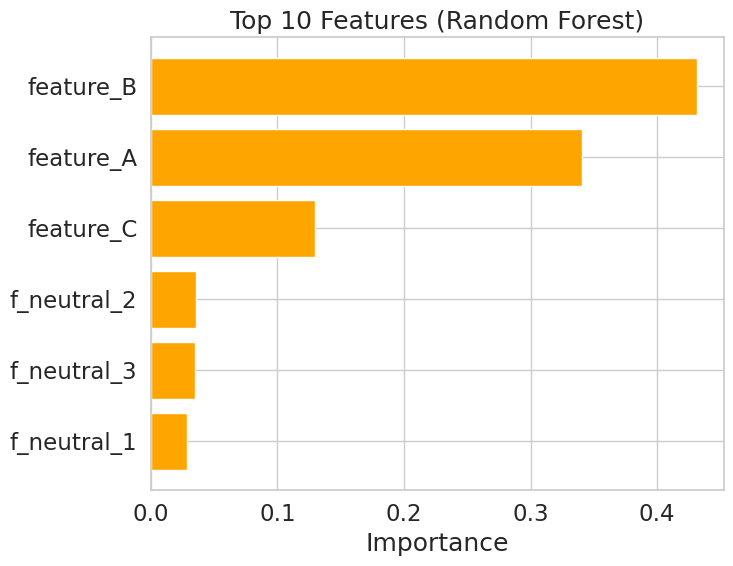

In [21]:
# Rank the top 10 features by Random Forest importance

importances_rf = pd.Series(rf.feature_importances_, index=X_train_top.columns).sort_values(ascending=False).head(10)

# Create figure and axes explicitly
fig, ax = plt.subplots(figsize=(10, 6))

# Plot directly on the axes
ax.barh(importances_rf.index[::-1], importances_rf.values[::-1], color='orange')
ax.set_xlabel('Importance')
ax.set_title('Top 10 Features (Random Forest)')

# Layout fixes
fig.tight_layout()
fig.subplots_adjust(left=0.4)  # ← this is now guaranteed to apply to the correct figure

# Save and show
# if save_path:
#     fig.savefig(save_path, format="jpeg", dpi=300, bbox_inches='tight')

plt.show()


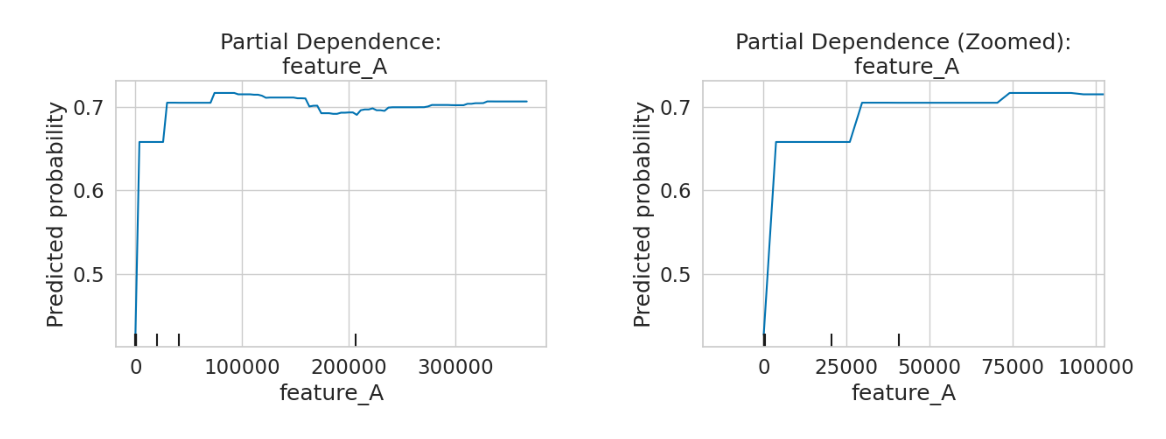

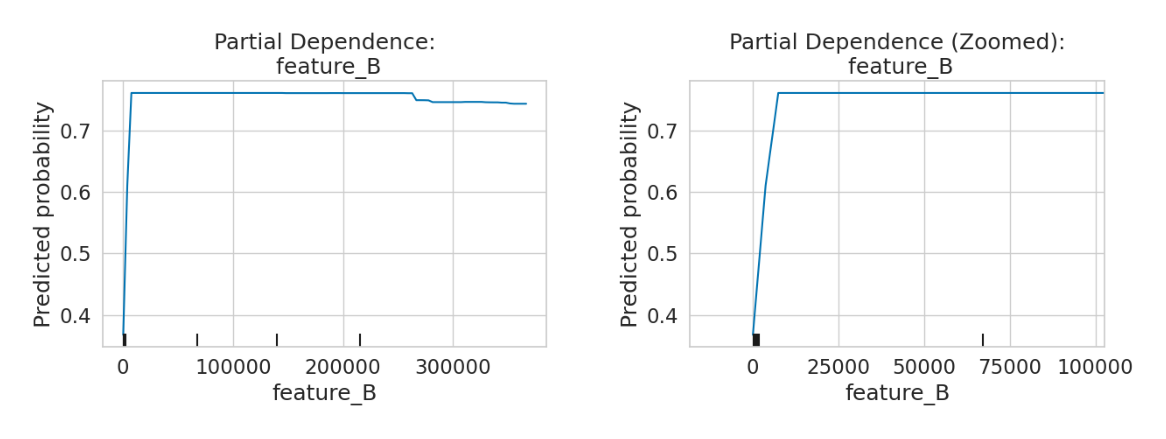

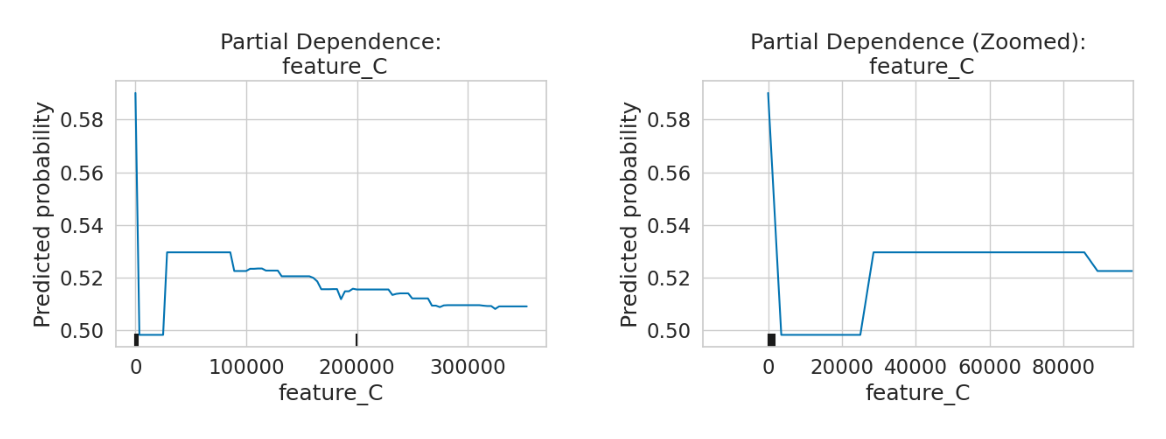

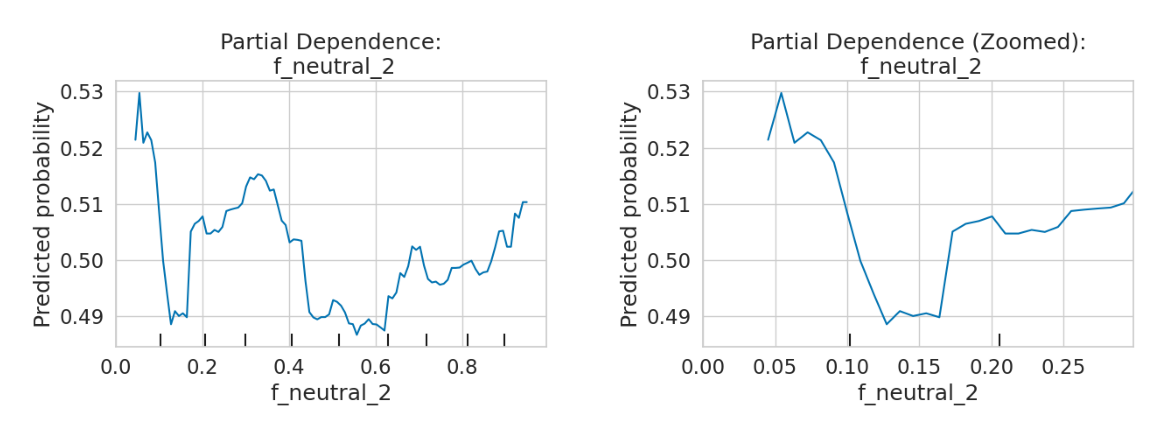

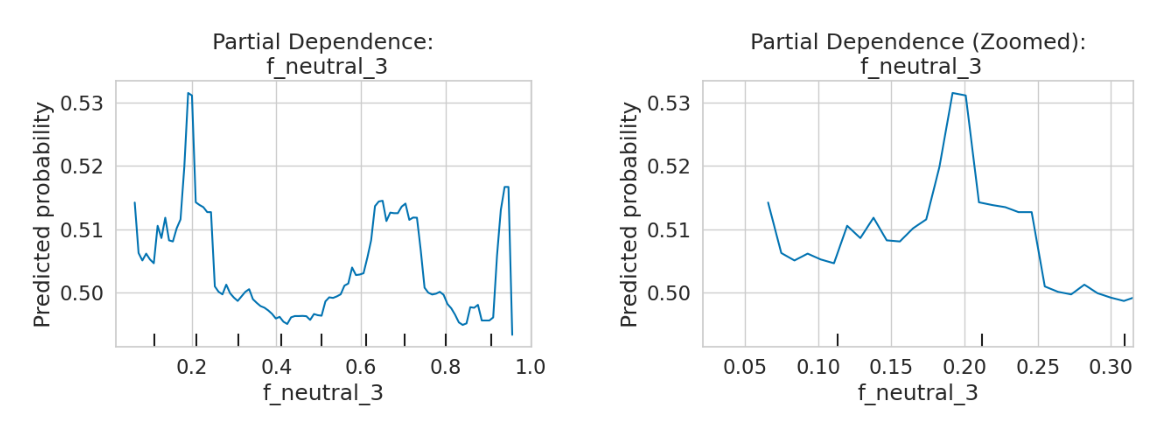

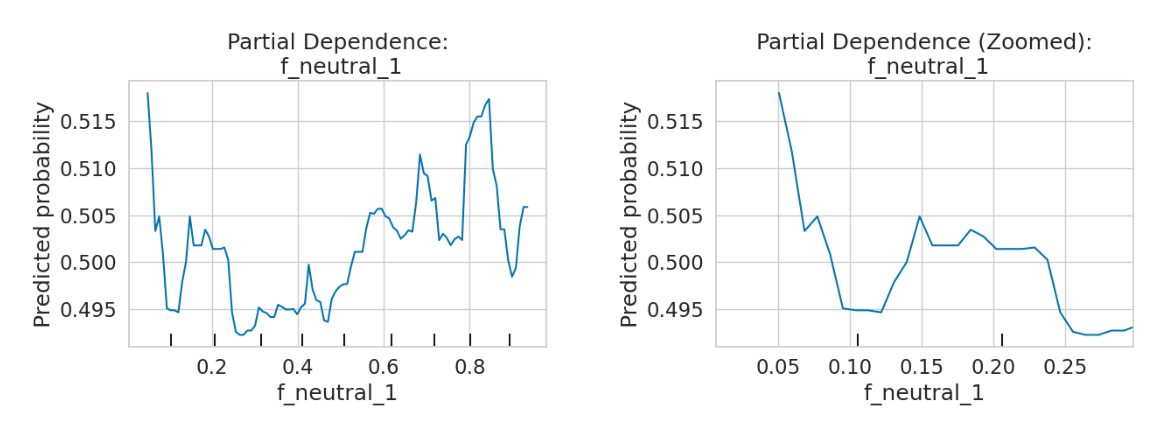

[CV] END bootstrap=False, max_depth=20, max_features=0.5, min_samples_leaf=4, min_samples_split=10, n_estimators=100; total time=   0.5s
[CV] END bootstrap=False, max_depth=10, max_features=0.3, min_samples_leaf=2, min_samples_split=5, n_estimators=500; total time=   1.3s
[CV] END bootstrap=False, max_depth=30, max_features=0.3, min_samples_leaf=8, min_samples_split=20, n_estimators=100; total time=   0.3s
[CV] END bootstrap=False, max_depth=30, max_features=0.3, min_samples_leaf=8, min_samples_split=20, n_estimators=100; total time=   0.3s
[CV] END bootstrap=True, max_depth=20, max_features=0.5, min_samples_leaf=4, min_samples_split=20, n_estimators=300; total time=   1.1s
[CV] END bootstrap=False, max_depth=20, max_features=0.5, min_samples_leaf=4, min_samples_split=2, n_estimators=200; total time=   1.0s
[CV] END bootstrap=True, max_depth=None, max_features=0.8, min_samples_leaf=1, min_samples_split=2, n_estimators=100; total time=   0.6s
[CV] END bootstrap=True, max_depth=30, max_f

In [22]:
# Partial dependence plots (PDPs) show how each feature's values affect
# the model's average predicted probability of a player being valuable.
# An upward trend suggests higher feature values are associated with
# a higher predicted probability; a downward trend suggests the opposite.
# These are model-based associations, not evidence of causation.
cms.plot_partial_dependence_grid(
    rf, X_train_top, top10_features, zoom_fraction=0.3
)

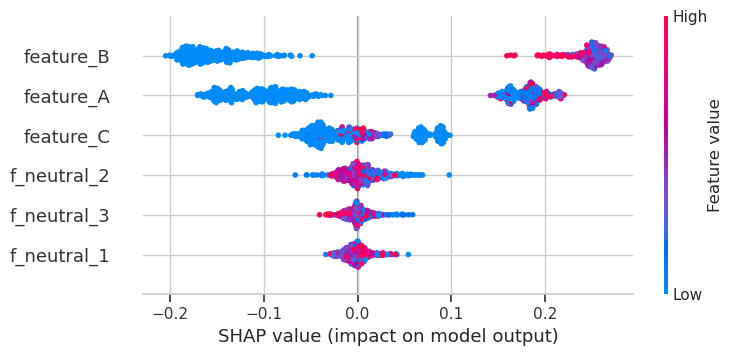

In [23]:
import shap

# SHAP explains how each feature contributes to the model's predictions.
# Summary plot guide:
# - Features are ranked by mean absolute SHAP value (overall importance).
# - Each dot represents one player.
# - Color: red = high feature value; blue = low feature value.
# - Positive SHAP values push predictions toward "valuable";
#   negative values push predictions toward "not valuable".
# - Wider horizontal spread indicates a stronger or more varied impact.
# Note: These are model-based associations, not proof of causation.

explainer = shap.TreeExplainer(rf, X_train_top)
shap_values = explainer.shap_values(X_test_top)

# Explain predictions for held-out test players
shap.summary_plot(shap_values[:, :, 1], X_test_top)

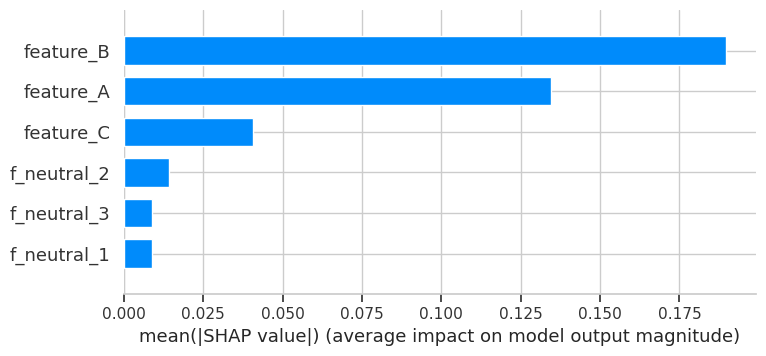

In [25]:
shap.summary_plot(shap_values[:, :, 1], X_test_top, plot_type="bar")

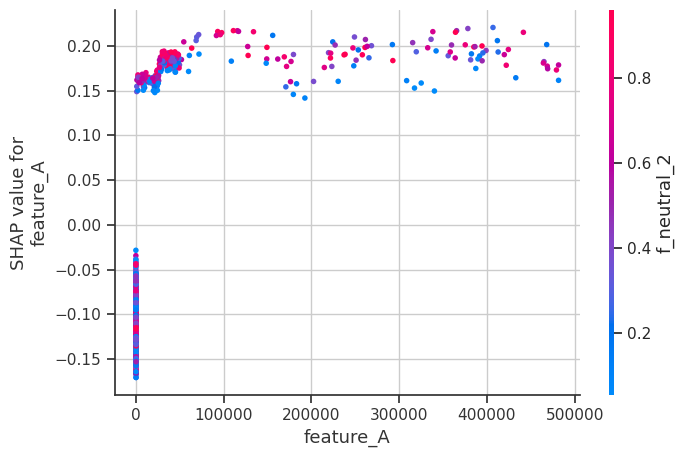

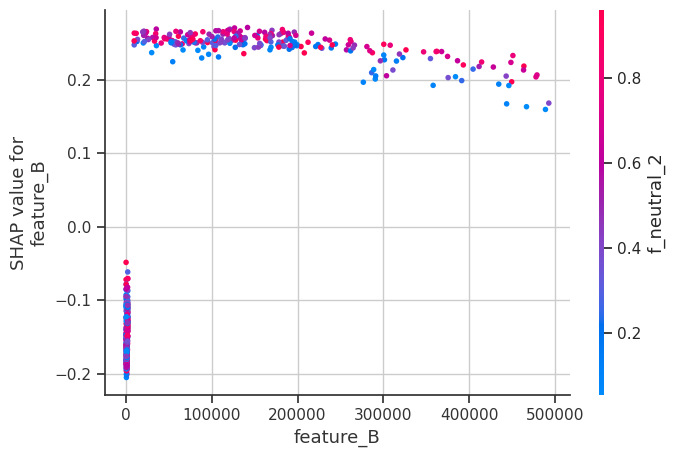

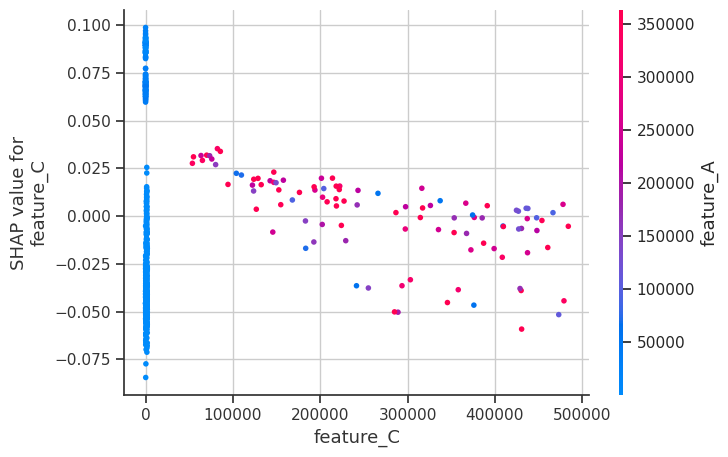

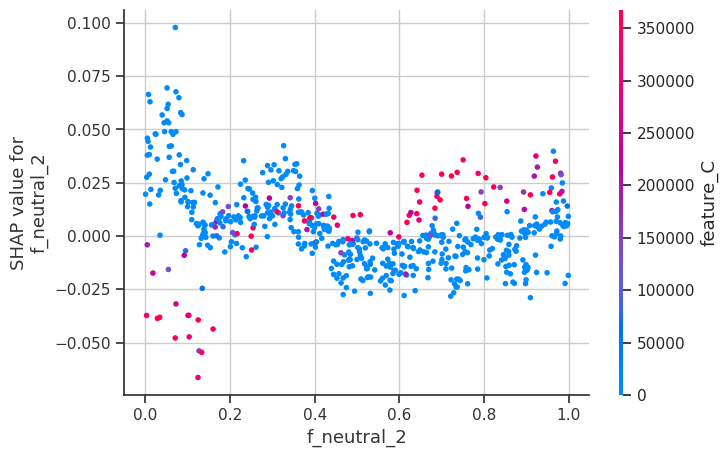

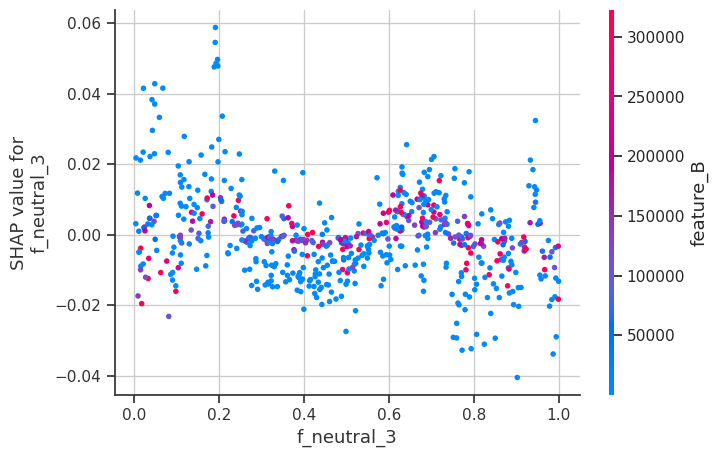

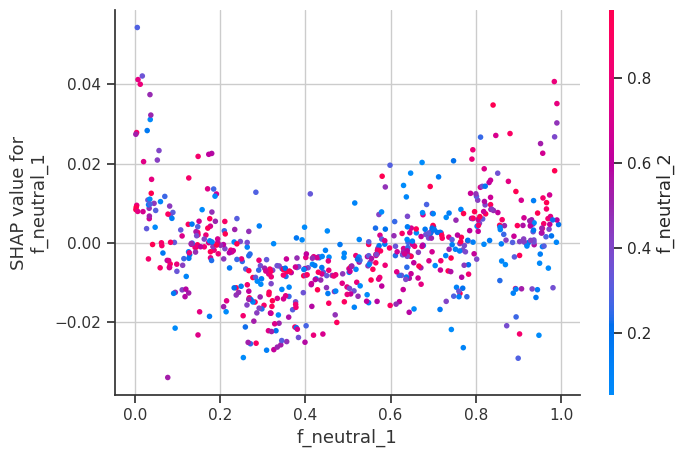

In [24]:
# Generate a SHAP dependence plot for each feature
# Each dot represents one player.
# - X-axis: the feature's actual value.
# - Y-axis: its SHAP value (contribution to the prediction).
# - Positive SHAP values push predictions toward "valuable";
#   negative values push them toward "not valuable".
# - Color represents another feature's value, potentially revealing interactions.
# Patterns show model-learned associations, not causal effects.

for feature in X_test_top.columns:
    shap.dependence_plot(feature, shap_values[:, :, 1], X_test_top)

## Conclusion

The analysis highlights the behavioral features most useful for distinguishing valuable players and explores how these features relate to model predictions. These findings can help generate hypotheses for improving player engagement and monetization. However, associations do not establish causation; controlled A/B tests would be needed to determine whether changing specific game features actually improves revenue.